Saved: C:\Master Physische Geographie\Canada\Masterarbeit\results\figures\variograms_together_20261011_113330.png
Ranch 1 nugget/sill/range: [-0.22071909 12.67333266  3.53129657]
Ranch 2 nugget/sill/range: [0.15388389 3.39408165 3.55405723]
Ranch 3 nugget/sill/range: [-0.04945598  4.97483308  3.9829614 ]


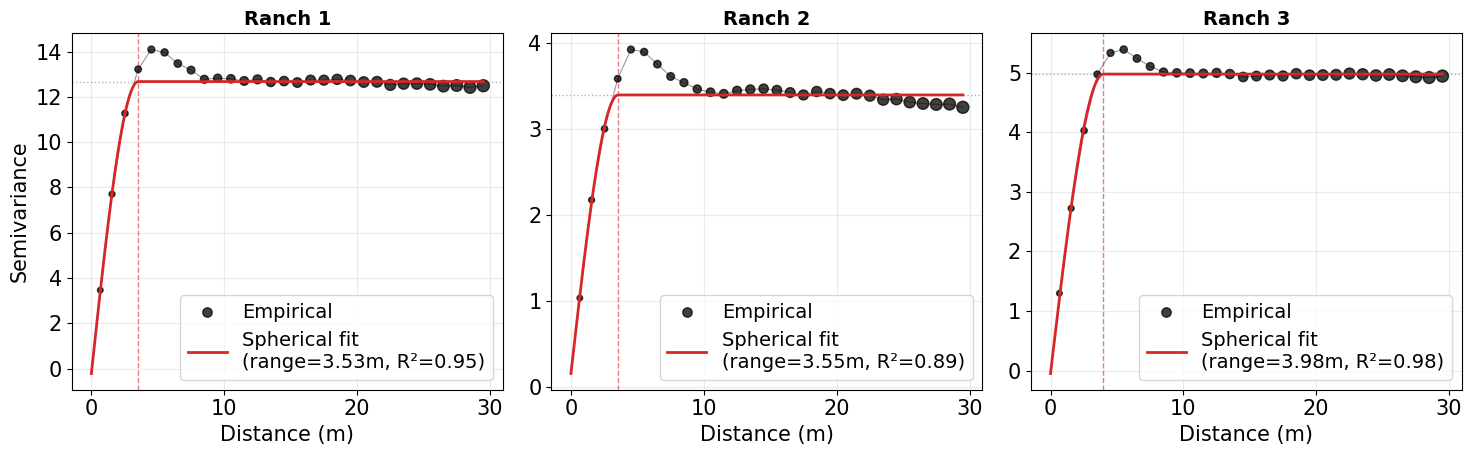

In [2]:
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import matplotlib as mpl
from datetime import datetime

mpl.rcParams['font.size'] = 15
mpl.rcParams['axes.titlesize'] = 13
mpl.rcParams['axes.titleweight'] = 'bold'

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

def spherical(h, nugget, sill, rng):
    return np.where(h <= rng,
                 nugget + (sill-nugget) * (1.5*(h/rng) - 0.5*(h/rng)**3),
                 sill)

# Point to your own variogram CSVs (columns: np, dist, gamma, dir.hor, dir.ver, id)
# Order left -> right: Ranch 5 (Ranch 1), Ranch 9 (Ranch 2), Ranch 12 (Ranch 3)
files = {
    'Ranch 1': r'C:\Master Physische Geographie\Canada\Masterarbeit\R\variogram_ranch5_data.csv',
    'Ranch 2': r'C:\Master Physische Geographie\Canada\Masterarbeit\R\variogram_ranch9_data.csv',
    'Ranch 3': r'C:\Master Physische Geographie\Canada\Masterarbeit\R\variogram_ranch12_data.csv',
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True)

fitted = {}
for ax, (ranch, path) in zip(axes, files.items()):
    df = pd.read_csv(path)
    h = df['dist'].values
    gamma = df['gamma'].values
    npairs = df['np'].values

    # Weighted nonlinear least squares fit (weights ~ 1/sqrt(pair count),
    # i.e. lags with more point pairs are trusted more)
    popt, _ = curve_fit(spherical, h, gamma, p0=[0.5, gamma.max(), 5.0],
                         sigma=1/np.sqrt(npairs), maxfev=20000)
    nugget, sill, rng = popt
    pred = spherical(h, *popt)
    ss_res = np.sum((gamma - pred) ** 2)
    ss_tot = np.sum((gamma - np.mean(gamma)) ** 2)
    r2 = 1 - ss_res / ss_tot
    fitted[ranch] = popt

    # marker size scaled by pair count, so bins with more support look bigger
    sizes = 15 + 60 * (npairs / npairs.max())

    ax.scatter(h, gamma, s=sizes, color='black', alpha=0.75, zorder=3, label='Empirical')
    ax.plot(h, gamma, color='black', lw=0.8, alpha=0.4, zorder=2)

    h_smooth = np.linspace(0, h.max(), 300)
    fit_smooth = spherical(h_smooth, *popt)
    ax.plot(h_smooth, fit_smooth, color='#d62728', lw=2, zorder=4,
            label=f'Spherical fit\n(range={rng:.2f}m, R²={r2:.2f})')

    ax.axvline(rng, color='#d62728', lw=1, ls='--', alpha=0.6)
    ax.axhline(sill, color='gray', lw=1, ls=':', alpha=0.6)

    ax.set_title(ranch, fontsize=14, fontweight='bold')
    ax.set_xlabel('Distance (m)')
    ax.legend(loc='lower right', fontsize=14, frameon=True)
    ax.grid(alpha=0.25)

axes[0].set_ylabel('Semivariance')

plt.tight_layout()
out = (rf"C:\Master Physische Geographie\Canada\Masterarbeit\results\figures"
       rf"\variograms_together_{timestamp}.png")
plt.savefig(out, dpi=200, bbox_inches='tight')
print("Saved:", out)
for ranch, popt in fitted.items():
    print(ranch, "nugget/sill/range:", popt)